# Tutorial 4 — Generate exactly 40 augmented JPEG images

Apply rotation, shear, zoom, horizontal flips and brightness changes. The default is a public example image; replace IMAGE_PATH with your own JPEG to repeat the assignment.

**How to run:** select a Python kernel with the repository requirements, then Run All. QUICK mode keeps experiments short. For the larger run set `TUTORIAL_FULL=1` before starting the kernel. A quick run demonstrates the method; it is not a final accuracy benchmark.

In [1]:
# Google Colab: fetch the support files and install missing dependencies.
# Local Jupyter: follow README setup once; this cell makes no changes.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    repo = Path("/content/dl-course-tutorials")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "https://github.com/naveed952/Tutorial-01_Perceptron_py.ipynb.git", str(repo)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo/"requirements.txt")])
    import os
    os.chdir(repo)


## Step 1 — Locate the project and set a reproducible seed
A fixed seed makes comparisons easier to reproduce. Each notebook can run independently.

In [2]:
from pathlib import Path
import sys, os
ROOT = Path.cwd() if (Path.cwd()/"tutorial_support").exists() else Path.cwd().parent
assert (ROOT/"tutorial_support").exists(), "Run from the repository or notebooks folder."
sys.path.insert(0, str(ROOT))
from tutorial_support.common import *
seed()
print("Mode:", "QUICK: small real-data run" if QUICK else "FULL: larger training run")

Mode: QUICK: small real-data run


## Step 2 — Load one JPEG and define the output directory
An image is H×W×C; adding a leading axis creates a batch with shape 1×H×W×C.

In [3]:
keras=keras_setup()
from PIL import Image
import matplotlib.pyplot as plt
IMAGE_PATH=sample_image() # replace with Path("your_image.jpg")
image=keras.utils.img_to_array(keras.utils.load_img(IMAGE_PATH,target_size=(224,224)))
batch=image[None,...];destination=OUT/'tutorial04_augmented';destination.mkdir(exist_ok=True)
print('Batch shape:',batch.shape)

Batch shape: (1, 224, 224, 3)


## Step 3 — Configure equivalent Keras preprocessing layers
The handout uses legacy ImageDataGenerator; these Keras 3 layers implement the same transformation categories. Transformations should preserve the label: a flower may be flipped, a handwritten 6 should not be rotated into a 9.

In [4]:
generator=keras.Sequential([keras.layers.RandomRotation(25/360,fill_mode='nearest',seed=SEED),keras.layers.RandomShear(x_factor=.15,y_factor=.0,seed=SEED+1),keras.layers.RandomZoom(.2,seed=SEED+2),keras.layers.RandomFlip('horizontal',seed=SEED+3),keras.layers.RandomBrightness(.3,value_range=(0,255),seed=SEED+4)])
paths=[]
for i in range(40):
    augmented=keras.ops.convert_to_numpy(generator(batch,training=True))[0]
    path=destination/f'aug_{i:02d}.jpg'
    keras.utils.save_img(path,augmented);paths.append(path)
assert len(paths)==40 and all(p.exists() for p in paths)
print('Saved 40 images to:',destination)

Saved 40 images to: D:\Disk E\Robotics And Ai\Deep  Learning\completed-tutorials\artifacts\tutorial04_augmented


## Step 4 — Inspect a grid and confirm label preservation
Augmentation happens only on training data. Forty transformations are correlated views of one source image, not forty independently collected observations. Always split by source before augmentation.

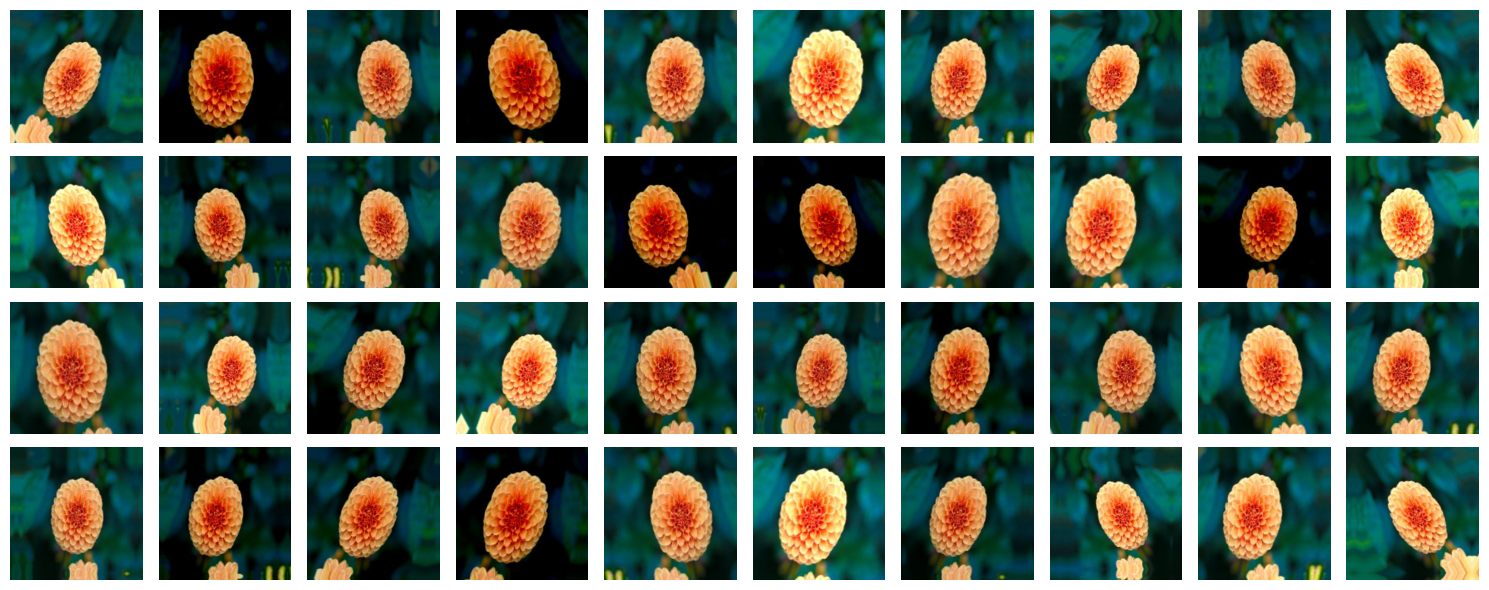

WindowsPath('D:/Disk E/Robotics And Ai/Deep  Learning/completed-tutorials/artifacts/04_augmentation.json')

In [5]:
fig,axes=plt.subplots(4,10,figsize=(15,6))
for ax,path in zip(axes.ravel(),paths):ax.imshow(Image.open(path));ax.axis('off')
plt.tight_layout();plt.show()
save_result('04_augmentation',{'count':len(paths),'source':'scikit-learn sample flower or IMAGE_PATH override'})

## Explain it in class
Describe the input, target, model, loss, update rule and evaluation split. Use the displayed results from your own run. Changing the dataset, seed or training budget can change the result.

**Course source:** the matching tutorial PDF supplied in the Deep Learning course. Original explanatory implementation; the course PDFs are not redistributed.